In [ ]:
# Housing Price Prediction using Linear Regression

This notebook demonstrates a housing price prediction model using Linear Regression.
The model predicts the price of a house based on its area in square feet.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [2]:
import pandas as pd

df = pd.read_csv("Housing_Price_Dataset.csv")

df.head(10)

,Area_sqft,Bedrooms,Bathrooms,Price_lakh
0,500,1,1,25
1,550,1,1,28
2,600,2,1,30
3,650,2,1,32
4,700,2,2,35
5,750,2,2,38
6,800,2,2,41
7,850,2,2,44
8,900,2,2,47
9,950,2,2,50


In [3]:
print("Dataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

print("\nStatistical Summary:")
df.describe()

Dataset Shape:
(30, 4)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Area_sqft   30 non-null     int64
 1   Bedrooms    30 non-null     int64
 2   Bathrooms   30 non-null     int64
 3   Price_lakh  30 non-null     int64
dtypes: int64(4)
memory usage: 1.1 KB
None

Statistical Summary:


,Area_sqft,Bedrooms,Bathrooms,Price_lakh
count,30.000000,30.000000,30.000000,30.000000
mean,1225.000000,2.600000,2.166667,66.866667
std,440.170422,0.770132,0.647719,26.479313
min,500.000000,1.000000,1.000000,25.000000
25%,862.500000,2.000000,2.000000,44.750000
50%,1225.000000,3.000000,2.000000,66.500000
75%,1587.500000,3.000000,3.000000,88.250000
max,1950.000000,4.000000,3.000000,113.000000


In [4]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Area_sqft     0
Bedrooms      0
Bathrooms     0
Price_lakh    0
dtype: int64


In [5]:
df = df.dropna()

print("Shape after removing missing values:")
print(df.shape)

Shape after removing missing values:
(30, 4)


In [ ]:
## Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the relationship between
house area and house price.

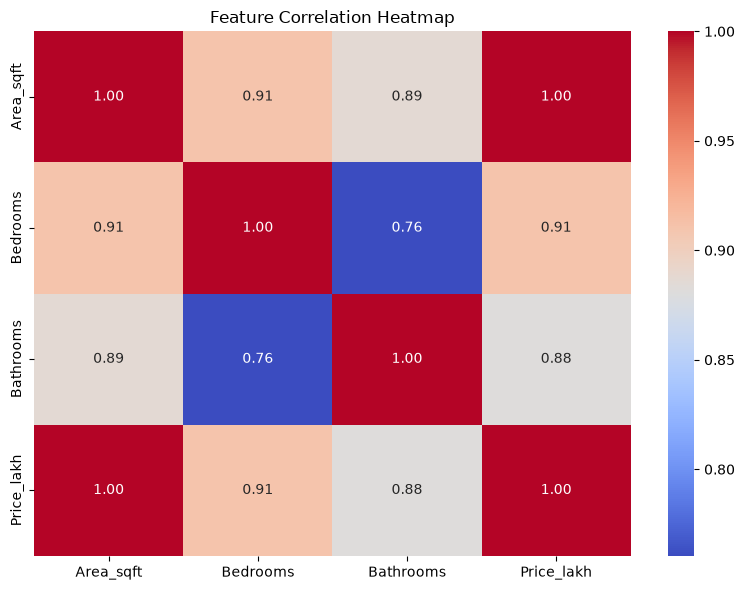

In [6]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

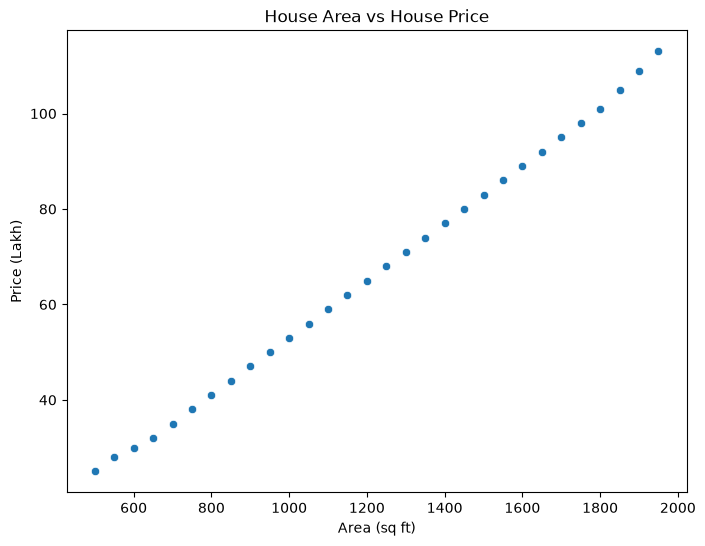

In [7]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="Area_sqft",
    y="Price_lakh"
)

plt.title("House Area vs House Price")
plt.xlabel("Area (sq ft)")
plt.ylabel("Price (Lakh)")

plt.show()

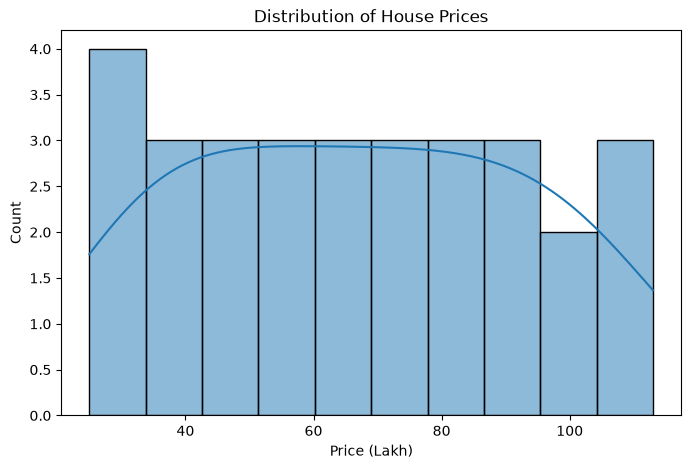

In [8]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["Price_lakh"],
    kde=True,
    bins=10
)

plt.title("Distribution of House Prices")
plt.xlabel("Price (Lakh)")

plt.show()

In [9]:
X = df[["Area_sqft"]]
y = df["Price_lakh"]

print("Input Feature X:")
print(X.head())

print("\nTarget Variable y:")
print(y.head())

Input Feature X:
   Area_sqft
0        500
1        550
2        600
3        650
4        700

Target Variable y:
0    25
1    28
2    30
3    32
4    35
Name: Price_lakh, dtype: int64


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (24, 1)
Testing data: (6, 1)


In [12]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


In [ ]:
## Model Training and Evaluation

A Linear Regression model is trained using the training dataset.

In [14]:
model = LinearRegression()

model.fit(X_train_scaled, y_train)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [15]:
y_pred = model.predict(X_test_scaled)

print("Predicted House Prices:")
print(y_pred)

Predicted House Prices:
[104.46371941  68.42028611  92.44924164  74.42752499  47.39495002
  50.39856946]


In [16]:
results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

results

,Actual Price,Predicted Price
0,105,104.463719
1,68,68.420286
2,92,92.449242
3,74,74.427525
4,47,47.394950
5,50,50.398569


In [17]:
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"R-squared (R2):      {r2:.4f}")
print(f"Mean Absolute Error: {mae:.4f}")
print(f"Root Mean Sq. Error: {rmse:.4f}")

R-squared (R2):      0.9996
Mean Absolute Error: 0.4378
Root Mean Sq. Error: 0.4404


In [18]:
coef_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

coef_df

,Feature,Coefficient
0,Area_sqft,26.962957


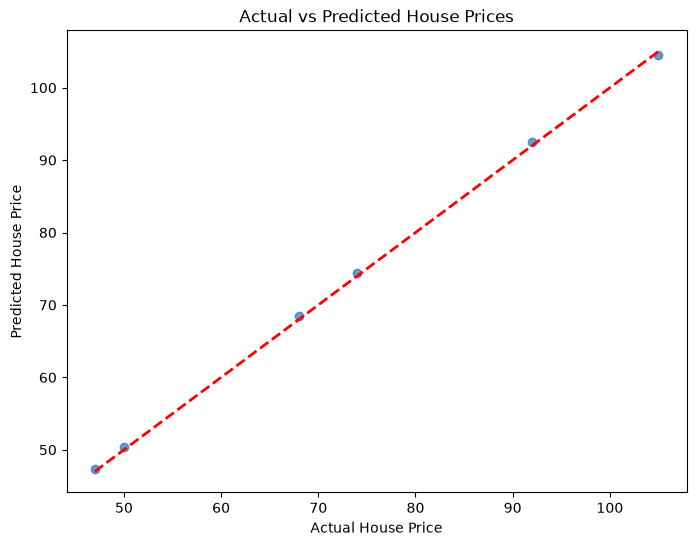

In [19]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--",
    lw=2
)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted House Prices")

plt.show()

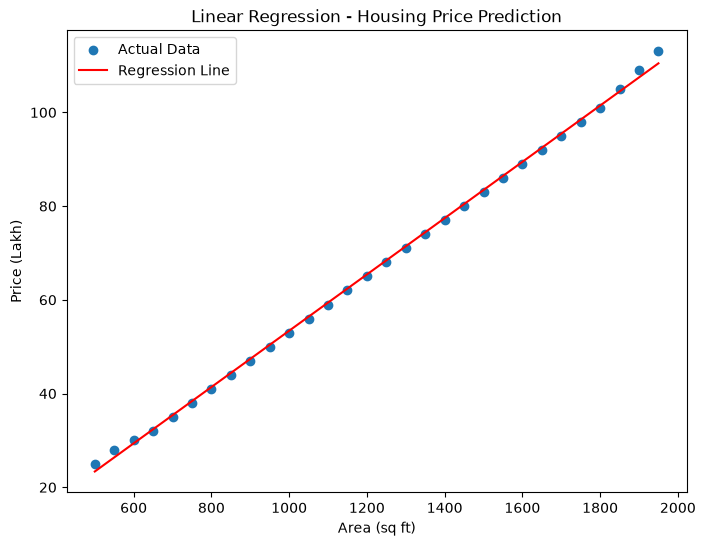

In [20]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df["Area_sqft"],
    df["Price_lakh"],
    label="Actual Data"
)

plt.plot(
    df["Area_sqft"],
    model.predict(scaler.transform(df[["Area_sqft"]])),
    color="red",
    label="Regression Line"
)

plt.xlabel("Area (sq ft)")
plt.ylabel("Price (Lakh)")
plt.title("Linear Regression - Housing Price Prediction")

plt.legend()
plt.show()

In [21]:
new_house = pd.DataFrame({
    "Area_sqft": [1250]
})

new_house_scaled = scaler.transform(new_house)

predicted_price = model.predict(new_house_scaled)

print(
    "Predicted price for 1250 sq ft house:",
    round(predicted_price[0], 2),
    "Lakh"
)

Predicted price for 1250 sq ft house: 68.42 Lakh
